# PersonalityLinMulT — Big Five showcase

Loads the current **champion** model with nothing but `pip install
personalitylinmult` (no MLflow, no repo clone needed for this part), runs it
on a **real** First Impressions V2 test clip, and compares the prediction
against the real ground-truth annotation.

**Champion**: `wavlm_best-ccc` — single-stream **LinT**, WavLM audio only,
trained with `ccc` loss at `batch_size=256` (the batch size fix that resolved
CCC's per-batch statistical noise — see `docs/experiments.md` for the full
story). Test `mean(1 - MAE) = 0.8918`, `mean CCC = 0.5604`,
`mean Pearson r = 0.5609`, `mean std_ratio = 1.0013` (near-perfect prediction
variance vs. ground-truth variance — the model commits to extremes rather
than hedging toward the mean).

> ⚠️ **License note.** The ChaLearn First Impressions V2 dataset's raw video
> and audio are not redistributed by this project (see `docs/dataset.md`) —
> this notebook expects **you** to have your own local copy of an FI clip,
> obtained through your own ChaLearn license. This repo only ships the
> ground-truth *annotation* for the example clip used below
> (`tests/fixtures/nLuAoNAOGcQ.005.annotation.json`), not the clip itself.
> The example clip referenced here (`nLuAoNAOGcQ.005.mp4`, official test
> split) was selected as the highest mean-trait clip in the test split —
> uniformly high across all five traits, a clear "extremely high" example.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Resolve paths from the repo root so the notebook runs regardless of the
# working directory it is launched from.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent

# Point this at your own local copy of the clip -- see the license note above.
CLIP_PATH = ROOT / "data" / "raw" / "FI" / "test" / "nLuAoNAOGcQ.005.mp4"
ANNOTATION_PATH = ROOT / "tests" / "fixtures" / "nLuAoNAOGcQ.005.annotation.json"

TRAITS = ["openness", "conscientiousness", "extraversion", "agreeableness", "emotional_stability"]

## 1. Load the champion model

Downloads (or reuses the cached) checkpoint from the public HF Hub model
repo. No MLflow, no training config, no repo clone required — this is exactly
what `pip install personalitylinmult` gives you.

In [2]:
from personalitylinmult import PersonalityModel

model = PersonalityModel.from_pretrained("wavlm_best-ccc")
print(f"Loaded. Needs features: {model.feature_names}. Predicts: {model.traits}")

Loaded. Needs features: ['wavlm']. Predicts: ['openness', 'conscientiousness', 'extraversion', 'agreeableness', 'emotional_stability']


## 2. Extract real features from the local clip

No pre-extraction step, no `fi.h5` — this is the same live-extraction path
the Gradio Space uses. The champion only needs WavLM (`model.feature_names ==
["wavlm"]`), so only WavLM is extracted, not the full acoustic set.

In [3]:
if not CLIP_PATH.is_file():
    raise FileNotFoundError(
        f"{CLIP_PATH} not found. This notebook needs your own local copy of an FI "
        "clip -- see the license note in the first cell."
    )

from personalitylinmult.inference.audio_features import extract_wavlm

wavlm = extract_wavlm(CLIP_PATH, device_id=-1)
print(f"WavLM: {wavlm.shape[0]} frames x {wavlm.shape[1]}")

features = {"wavlm": wavlm}
scores = model.predict(features)
scores

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

WavLM: 764 frames x 768


{'openness': 0.8953461647033691,
 'conscientiousness': 0.7527333498001099,
 'extraversion': 0.7722039818763733,
 'agreeableness': 0.8005387783050537,
 'emotional_stability': 0.8410302400588989}

## 3. Predicted vs. ground truth

This clip's real annotator ratings are uniformly high across all five traits
(mean 0.866) — a genuinely strong "extremely high personality" example, not a
cherry-picked easy case.

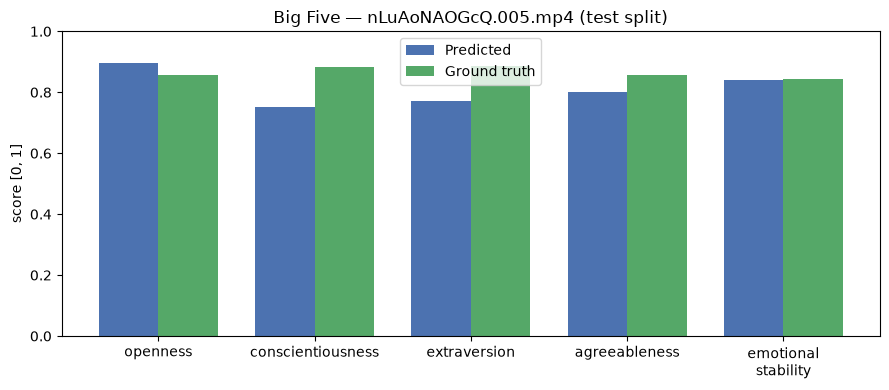

In [4]:
annotation = json.loads(ANNOTATION_PATH.read_text())
ground_truth = annotation["traits"]

x = np.arange(len(TRAITS))
w = 0.38
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - w / 2, [scores[t] for t in TRAITS], w, label="Predicted", color="#4C72B0")
ax.bar(x + w / 2, [ground_truth[t] for t in TRAITS], w, label="Ground truth", color="#55A868")
ax.set_xticks(x)
ax.set_xticklabels([t.replace("_", "\n") for t in TRAITS])
ax.set_ylim(0, 1)
ax.set_ylabel("score [0, 1]")
ax.set_title(f"Big Five — {annotation['video_id']} (test split)")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Interpretation

This is a **single clip**, not a benchmark — the model's real test-set
numbers (`mean_one_minus_mae=0.8918`, `mean_ccc=0.5604`) are the reliable
measure of quality; see `docs/experiments.md` for the full comparison across
every loss/batch-size variant tried. What this one example shows concretely:
whether the champion's predictions land in the same *high* region as this
clip's genuinely high ground truth, or regress toward the population mean —
the exact failure mode `std_ratio` was built to catch (see
`personalitylinmult/train/metrics.py`), and the reason this model was chosen
over the earlier elementwise-loss baselines that scored a similar 1-MAE while
collapsing prediction variance toward the training mean.

In [5]:
errors = {t: abs(scores[t] - ground_truth[t]) for t in TRAITS}
for trait, err in errors.items():
    print(f"{trait:22s} pred={scores[trait]:.3f}  true={ground_truth[trait]:.3f}  |err|={err:.3f}")
print(f"\nmean absolute error on this clip: {sum(errors.values()) / len(errors):.3f}")

openness               pred=0.895  true=0.856  |err|=0.040
conscientiousness      pred=0.753  true=0.883  |err|=0.131
extraversion           pred=0.772  true=0.888  |err|=0.116
agreeableness          pred=0.801  true=0.857  |err|=0.057
emotional_stability    pred=0.841  true=0.844  |err|=0.003

mean absolute error on this clip: 0.069


## 5. PyTorch vs. ONNX: full pipeline, on a fixture clip

Everything above needs your own licensed FI clip. This section does not --
it generates a short synthetic audio fixture with `ffmpeg` (no dataset
license involved) and runs the **full** audio-to-prediction pipeline through
both backends this project supports:

- **PyTorch** (`personalitylinmult`, `torch`/`lightning`): manual
  extract-then-predict, matching what `FiPredictor`/`PersonalityModel` do.
- **ONNX** (`personalitylinmult[onnx]`, `onnxruntime` only):
  `PersonalityModelONNX.predict_from_audio`, one call, no `torch` needed.

Install extras first: `uv sync --extra train --extra demo --extra onnx`
(`train` for the base PyTorch path, `demo` for `exordium`'s live WavLM
extraction -- the same dependency the Gradio Space needs -- and `onnx`
for the ONNX Runtime path).

In [6]:
import subprocess
import tempfile
import time

FIXTURE_CLIP = Path(tempfile.mkstemp(suffix=".wav")[1])
subprocess.run(
    ["ffmpeg", "-y", "-f", "lavfi", "-i", "sine=frequency=440:duration=3", str(FIXTURE_CLIP)],
    capture_output=True,
    check=True,
)
print(f"Fixture clip: {FIXTURE_CLIP}")

Fixture clip: /var/folders/gt/fx6xjk313gjd_dt47wjm943h0000gn/T/tmpl2waen_0.wav


### PyTorch path

In [7]:
# Warm up (model load + first-call overhead), then time a clean run.
_ = model.predict({"wavlm": extract_wavlm(FIXTURE_CLIP, device_id=-1)})

t0 = time.perf_counter()
pytorch_features = extract_wavlm(FIXTURE_CLIP, device_id=-1)
pytorch_scores = model.predict({"wavlm": pytorch_features})
pytorch_time = time.perf_counter() - t0

print(f"PyTorch: {pytorch_time * 1000:.1f} ms")
pytorch_scores

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

PyTorch: 972.1 ms


{'openness': 0.1616186946630478,
 'conscientiousness': 0.06833294779062271,
 'extraversion': 0.12619182467460632,
 'agreeableness': 0.0,
 'emotional_stability': 0.054117120802402496}

### ONNX path

Full pipeline in one call — no `torch` used from here on.

In [8]:
from personalitylinmult.onnx import PersonalityModelONNX

onnx_model = PersonalityModelONNX.from_pretrained("wavlm_best-ccc")

# Warm up (downloads WavLM's ONNX graph on first use, then caches it).
_ = onnx_model.predict_from_audio(str(FIXTURE_CLIP))

t0 = time.perf_counter()
onnx_scores = onnx_model.predict_from_audio(str(FIXTURE_CLIP))
onnx_time = time.perf_counter() - t0

print(f"ONNX: {onnx_time * 1000:.1f} ms")
onnx_scores

ONNX: 158.1 ms


{'openness': 0.16214224696159363,
 'conscientiousness': 0.06391233950853348,
 'extraversion': 0.12680169939994812,
 'agreeableness': 0.0,
 'emotional_stability': 0.05370957776904106}

### Compare

Predictions should be close but not bit-identical — `ffmpeg`'s resampler and
`torchaudio`'s differ slightly (see `docs/experiments.md`, Block 6), which is
why the ONNX path is measurably faster and *approximately*, not exactly, the
same as the PyTorch path.

In [9]:
speedup = pytorch_time / onnx_time
print(f"speedup: {speedup:.1f}x\n")

print(f"{'trait':<22} {'pytorch':>10} {'onnx':>10} {'diff':>10}")
for t in TRAITS:
    diff = abs(pytorch_scores[t] - onnx_scores[t])
    print(f"{t:<22} {pytorch_scores[t]:>10.4f} {onnx_scores[t]:>10.4f} {diff:>10.4f}")

FIXTURE_CLIP.unlink(missing_ok=True)

speedup: 6.1x

trait                     pytorch       onnx       diff
openness                   0.1616     0.1621     0.0005
conscientiousness          0.0683     0.0639     0.0044
extraversion               0.1262     0.1268     0.0006
agreeableness              0.0000     0.0000     0.0000
emotional_stability        0.0541     0.0537     0.0004


## 6. The full multimodal (AVT) champion

Everything above uses `wavlm_best-ccc` (LinT, audio-only). This project's other champion, `avt_best-ccc` (LinMulT), fuses all three modalities -- audio, video frames, and text -- and scores higher on every metric except `std_ratio` (see `docs/experiments.md`). It is only available through the **ONNX** backend: `predict_from_media` orchestrates face detection/tracking, six ONNX feature extractors, and the trained LinMulT head in one call.

Like section 5, this uses a synthetic `ffmpeg` fixture (no dataset license involved) -- a real clip would need a genuine face for the EmotiEffNet/FaRL features to be non-zero, but the pipeline itself runs identically either way, gracefully falling back to zero features when no protagonist face is found (logged as a warning, not an error).

In [10]:
AVT_FIXTURE_CLIP = Path(tempfile.mkstemp(suffix=".mp4")[1])
subprocess.run(
    [
        "ffmpeg",
        "-y",
        "-f",
        "lavfi",
        "-i",
        "testsrc=duration=1:size=64x64:rate=5",
        "-f",
        "lavfi",
        "-i",
        "sine=frequency=440:duration=1",
        "-c:v",
        "libx264",
        "-c:a",
        "aac",
        "-shortest",
        str(AVT_FIXTURE_CLIP),
    ],
    capture_output=True,
    check=True,
)
print(f"AVT fixture clip: {AVT_FIXTURE_CLIP}")

AVT fixture clip: /var/folders/gt/fx6xjk313gjd_dt47wjm943h0000gn/T/tmpsq49st41.mp4


### Load the AVT champion and predict

Three ways to handle the transcript, matching `predict_from_media`'s contract: pass a real string, omit it (`transcript=None`, runs Whisper ASR automatically), or pass `""` to skip text entirely (a zero placeholder + all-False mask for the text features -- verified NaN-safe, see `tests/inference/test_linmult_mask_validation.py`). This notebook uses the third option to avoid a Whisper download for a demo fixture with no real speech content.

In [11]:
from personalitylinmult.onnx import PersonalityModelONNX

avt_model = PersonalityModelONNX.from_pretrained("avt_best-ccc")
print(f"Loaded. Needs features: {avt_model.feature_names}")

t0 = time.perf_counter()
avt_scores = avt_model.predict_from_media(str(AVT_FIXTURE_CLIP), transcript="")
avt_time = time.perf_counter() - t0
print(f"\npredict_from_media: {avt_time:.2f}s\n")
for t in TRAITS:
    print(f"{t:<22} {avt_scores[t]:>10.4f}")

AVT_FIXTURE_CLIP.unlink(missing_ok=True)

Loaded. Needs features: ['wavlm', 'emotion2vec', 'dinov2', 'emotieffnet', 'farl', 'xlm_roberta_gt', 'mmbert_gt']


objc[67309]: Class AVFFrameReceiver is implemented in both /opt/homebrew/Cellar/ffmpeg/8.1.2_1/lib/libavdevice.62.3.102.dylib (0x122658328) and /Volumes/UGREEN/Dev/PersonalityLinMulT/.venv/lib/python3.13/site-packages/cv2/.dylibs/libavdevice.61.3.100.dylib (0x12650c3a8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[67309]: Class AVFAudioReceiver is implemented in both /opt/homebrew/Cellar/ffmpeg/8.1.2_1/lib/libavdevice.62.3.102.dylib (0x122658378) and /Volumes/UGREEN/Dev/PersonalityLinMulT/.venv/lib/python3.13/site-packages/cv2/.dylibs/libavdevice.61.3.100.dylib (0x12650c3f8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.


/var/folders/gt/fx6xjk313gjd_dt47wjm943h0000gn/T/tmpsq49st41.mp4: no protagonist face track found; using zero features.



predict_from_media: 6.87s

openness                   0.4449
conscientiousness          0.4943
extraversion               0.3510
agreeableness              0.1077
emotional_stability        0.3839
